# Wstęp do przetwarzania języka naturalnego

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import Dataset, DataLoader

torch.manual_seed(1)

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.mps.is_available() else "cpu") 
device

device(type='mps')

### Średniowieczne podejścia - bag of words

In [4]:
from bs4 import BeautifulSoup
import re

In [5]:
# data from https://github.com/clairett/pytorch-sentiment-classification/tree/master
reviews = pd.read_csv("./lab13_nlp_train.tsv",delimiter="\t",quoting=3,names=["sentence", "label"]).reset_index(drop=True)

In [6]:
reviews

,sentence,label
0,"a stirring , funny and finally transporting re...",1
1,apparently reassembled from the cutting room f...,0
2,they presume their audience wo n't sit still f...,0
3,this is a visually stunning rumination on love...,1
4,jonathan parker 's bartleby should have been t...,1
...,...,...
6915,"painful , horrifying and oppressively tragic ,...",1
6916,take care is nicely performed by a quintet of ...,0
6917,"the script covers huge , heavy topics in a bla...",0
6918,a seriously bad film with seriously warped log...,0


In [7]:
print(reviews["sentence"][4])

jonathan parker 's bartleby should have been the be all end all of the modern office anomie films


In [8]:
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/kwasus/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [9]:
from nltk.corpus import stopwords
print(stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [ ]:
def review_to_words(raw_review):
    """Function to convert a review to a string of words.
    The input is a single string (a raw moviw review), and the output is a single string (a preprocessed movie review)"""
    review_text = BeautifulSoup(raw_review, 'lxml').get_text()
    letters_only = re.sub("[^a-zA-Z]", " ", review_text)
    words = letters_only.lower().split()
    stops = set(stopwords.words('english'))
    meaningful_words = [word for word in words if word not in stops]
    return " ".join(meaningful_words)

In [11]:
clean_review = review_to_words(reviews['sentence'][4])
print(clean_review)

jonathan parker bartleby end modern office anomie films


In [13]:
num_reviews = reviews['sentence'].size

# Initialize an empty list to hold the clean reviews
clean_train_reviews = []

# Loop over each review; create an index i that goes from 0 to the length of the move review list
for review in range(0, num_reviews):
    # If the index is evenly divisible by 100, print a message
    if (review+1) % 1000 == 0:
        print('Review {} of {}'.format(review+1, num_reviews))
    # Call our function for each one, and add the result to the list of clean reviews
    clean_train_reviews.append(review_to_words(reviews['sentence'][review]))

Review 1000 of 6920
Review 2000 of 6920
Review 3000 of 6920
Review 4000 of 6920
Review 5000 of 6920
Review 6000 of 6920


In [14]:
print('Creating the bag of words...')
from sklearn.feature_extraction.text import CountVectorizer

# Initialize the "CountVectorizer" object, which is scikit-learn's bag of words tool.
vectorizer = CountVectorizer(analyzer = 'word',
                            tokenizer = None,
                            preprocessor = None,
                            stop_words = None,
                            max_features = 1000)
# fit_transform() does two functions: First, it fits the model
# and learns the vocaulary; second, it transforms our training data
# into feature vectors. The input to fit_transform should be a list of strings.
train_data_features = vectorizer.fit_transform(clean_train_reviews)

# Numpy arrays are easy to work with, so convert the result to an array
train_data_features = train_data_features.toarray()
print('Bag of words completed')

Creating the bag of words...
Bag of words completed


In [15]:
vocab = vectorizer.get_feature_names_out()
print(len(vocab))

1000


In [16]:
vocab

array(['ability', 'able', 'absolutely', 'absorbing', 'across', 'act',
       'acted', 'acting', 'action', 'actor', 'actors', 'actress',
       'actually', 'adaptation', 'add', 'adults', 'adventure', 'age',
       'ages', 'ago', 'air', 'allen', 'allows', 'almost', 'alone',
       'along', 'already', 'also', 'although', 'always', 'amazing',
       'ambitious', 'america', 'american', 'among', 'amount', 'amusing',
       'animated', 'animation', 'another', 'anyone', 'anything', 'apart',
       'appeal', 'appealing', 'approach', 'around', 'art', 'artist',
       'attempt', 'attempts', 'attention', 'attraction', 'audience',
       'audiences', 'average', 'away', 'awful', 'back', 'bad', 'barely',
       'based', 'battle', 'bears', 'beautiful', 'beautifully', 'beauty',
       'become', 'becomes', 'begins', 'behind', 'believable', 'believe',
       'best', 'better', 'beyond', 'big', 'bit', 'black', 'bland',
       'blood', 'blue', 'bond', 'book', 'boring', 'boy', 'boys',
       'brilliant', 'br

In [17]:
train_indices = np.random.rand(len(reviews))>0.3
train_data = torch.from_numpy(train_data_features).float()[train_indices]
train_targets = torch.from_numpy(reviews["label"].values[train_indices]).long()

test_data = torch.from_numpy(train_data_features[~train_indices]).float()
test_targets = torch.from_numpy(reviews["label"].values[~train_indices]).long()

In [18]:
train_dataset = data.TensorDataset(train_data,train_targets)
test_dataset = data.TensorDataset(test_data,test_targets)

In [19]:
train_loader = data.DataLoader(train_dataset, batch_size=64, shuffle=True, drop_last=True)
test_loader = data.DataLoader(test_dataset, batch_size=128, shuffle=False)

In [20]:
class BoWClassifier(nn.Module):
    def __init__(self): 
        super(BoWClassifier, self).__init__()
        self.lin1 =nn.Linear(1000, 500)
        self.act1 =nn.LeakyReLU()
        self.lin2 =nn.Linear(500, 50)
        self.act2 =nn.LeakyReLU()
        self.lin3 =nn.Linear(50, 2)
        
             
    def forward(self, x):
        x = self.lin1(x)
        x = self.act1(x)
        x = self.lin2(x)
        x = self.act2(x)
        x = self.lin3(x)
        return x
bow_model = BoWClassifier().to(device)
bow_model

BoWClassifier(
  (lin1): Linear(in_features=1000, out_features=500, bias=True)
  (act1): LeakyReLU(negative_slope=0.01)
  (lin2): Linear(in_features=500, out_features=50, bias=True)
  (act2): LeakyReLU(negative_slope=0.01)
  (lin3): Linear(in_features=50, out_features=2, bias=True)
)

In [21]:
def get_accuracy(model, data_loader):
    correct = 0
    total = 0
    model.eval() #*********#
    for imgs, labels in data_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        output = model(imgs)
        pred = output.max(1, keepdim=True)[1] # get the index of the max logit
        correct += pred.eq(labels.view_as(pred)).sum().item()
        total += imgs.shape[0]
    return correct / total

In [22]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(bow_model.parameters(), lr=0.001)

iters = []
losses = []
train_acc = []
val_acc = []
for n in range(10):
    epoch_losses = []
    for x, labels in iter(train_loader):
        x, labels = x.to(device), labels.to(device)
        bow_model.train() 
        out = bow_model(x).squeeze()           

        loss = criterion(out, labels)
        loss.backward()  
        epoch_losses.append(loss.item())
        optimizer.step()              
        optimizer.zero_grad()         

    loss_mean = np.array(epoch_losses).mean()
    iters.append(n)
    losses.append(loss_mean)
    test_acc = get_accuracy(bow_model, test_loader)
    print(f"Epoch {n} loss {loss_mean:.3} test_acc: {test_acc:.3}")
    train_acc.append(get_accuracy(bow_model, train_loader)) # compute training accuracy 
    val_acc.append(test_acc)  # compute validation accuracy
        

print("Final Training Accuracy: {}".format(train_acc[-1]))
print("Final Validation Accuracy: {}".format(val_acc[-1]))

Epoch 0 loss 0.625 test_acc: 0.738
Epoch 1 loss 0.438 test_acc: 0.733
Epoch 2 loss 0.329 test_acc: 0.741
Epoch 3 loss 0.227 test_acc: 0.742
Epoch 4 loss 0.132 test_acc: 0.739
Epoch 5 loss 0.0814 test_acc: 0.734
Epoch 6 loss 0.0548 test_acc: 0.729
Epoch 7 loss 0.0456 test_acc: 0.734
Epoch 8 loss 0.0399 test_acc: 0.732
Epoch 9 loss 0.0385 test_acc: 0.737
Final Training Accuracy: 0.984375
Final Validation Accuracy: 0.7372093023255814


In [23]:
example_1_text = "I do not like this movie"
example_2_text = "I like this movie"
examples = vectorizer.transform([review_to_words(example_1_text),review_to_words(example_2_text)])
examples = torch.from_numpy(examples.toarray()).to(device).float()
bow_model(examples)

tensor([[-0.7954,  0.7576],
        [-0.7954,  0.7576]], device='mps:0', grad_fn=<LinearBackward0>)

### let's see what preprocessing did

In [24]:
review_to_words(example_1_text),review_to_words(example_2_text)

('like movie', 'like movie')

In [25]:
example_1_text = "The topic of this movie is love"
example_2_text = "I love a movie about this topic"
examples = vectorizer.transform([review_to_words(example_1_text),review_to_words(example_2_text)])
examples = torch.from_numpy(examples.toarray()).to(device).float()
bow_model(examples)

tensor([[-2.6247,  2.5897],
        [-2.6247,  2.5897]], device='mps:0', grad_fn=<LinearBackward0>)

In [26]:
review_to_words(example_1_text),review_to_words(example_2_text)

('topic movie love', 'love movie topic')

### Embeddingi w języku

In [27]:
pip install gensim

/Users/kwasus/Desktop/STUDIA/SEM6/SSNE/Neural-Network-Concepts/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [28]:
import gensim.downloader as api
from gensim.models.word2vec import Word2Vec
corpus = api.load('text8') #text8 dataset loaded from Gensim
gensim_model = Word2Vec(corpus) #trains on corpus

[==================================================] 100.0% 31.6/31.6MB downloaded


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


In [29]:
gensim_model.wv["king"]

array([-1.189655  ,  2.2760217 ,  0.41186452,  1.5429621 , -1.0478296 ,
       -0.2593658 ,  1.9304265 ,  5.0300903 ,  1.7415437 ,  0.5182594 ,
        0.3712556 , -3.016979  ,  0.9280452 ,  2.1584733 , -1.4447179 ,
       -1.3694044 ,  1.5522054 ,  1.4211284 ,  2.8966663 , -0.7753784 ,
       -0.5937974 ,  2.498858  , -1.7519509 , -2.3326974 , -1.6013472 ,
        0.26205888,  0.05987504,  0.37736037,  1.2362162 , -1.9929786 ,
       -0.2252798 , -0.93594897,  0.49145493,  1.4227574 ,  1.7854519 ,
       -1.7409042 ,  1.3491302 , -1.4832871 ,  2.9356701 ,  0.02341568,
        0.17269991,  2.7093754 ,  0.47751772, -1.1415164 , -1.798397  ,
       -1.7616534 , -1.7167493 , -0.15218185,  0.99255574, -1.2600523 ,
        4.87979   , -1.5200454 , -2.078143  ,  1.5053056 ,  0.76847744,
       -1.2079533 , -0.20457831,  0.09339976, -0.9362911 , -2.0355973 ,
        1.7310529 ,  0.75273895,  0.9637864 , -0.8559305 ,  0.0842554 ,
       -2.127122  , -1.1686214 ,  0.13203289,  1.9274006 , -0.21

In [30]:
gensim_model.wv.most_similar("king")

[('prince', 0.7520701885223389),
 ('queen', 0.7127968072891235),
 ('emperor', 0.7057456970214844),
 ('kings', 0.6927893757820129),
 ('throne', 0.686883270740509),
 ('regent', 0.6720214486122131),
 ('vii', 0.6635995507240295),
 ('constantine', 0.6588303446769714),
 ('elector', 0.6503049731254578),
 ('pharaoh', 0.6417087316513062)]

In [31]:
gensim_model.wv.most_similar("car")

[('driver', 0.8003045916557312),
 ('motorcycle', 0.7453020215034485),
 ('cars', 0.715472400188446),
 ('vehicle', 0.705973744392395),
 ('taxi', 0.6925268769264221),
 ('racing', 0.6839046478271484),
 ('truck', 0.6751071214675903),
 ('volkswagen', 0.6515524387359619),
 ('automobile', 0.6454862356185913),
 ('passenger', 0.6353371143341064)]

In [32]:
gensim_model.wv.most_similar("love")

[('passion', 0.6379692554473877),
 ('me', 0.6276333332061768),
 ('loving', 0.6125783324241638),
 ('thee', 0.6017560958862305),
 ('grace', 0.6005434393882751),
 ('my', 0.5976078510284424),
 ('praise', 0.5929533839225769),
 ('kindness', 0.5900954604148865),
 ('happiness', 0.5862869024276733),
 ('enthusiasm', 0.585370659828186)]

### Word as nn.embedding - minimal example

In [33]:
word_to_ix = {"hello": 0, "world": 1}
embeds = nn.Embedding(2, 5)  # 2 words in vocab, 5 dimensional embeddings
lookup_tensor = torch.tensor([word_to_ix["hello"]], dtype=torch.long)
hello_embed = embeds(lookup_tensor)
print(hello_embed)

tensor([[ 0.3320,  2.3638,  0.8769,  0.1382, -0.3959]],
       grad_fn=<EmbeddingBackward0>)


#### Czyli wklejamy warstwę nn.Embedding uczymy tak jak powyżej i już?

## Continuous Bag-of-Words - przewidywanie słowa na podstawie kontekstu

In [34]:
CONTEXT_SIZE = 2 #CONTEXT_SIZE = 2, so for each target word, you take 2 words before and 2 words after it
EMBEDDING_DIM = 10
test_sentence = """We are about to study the idea of a computational process.
Computational processes are abstract beings that inhabit computers.
As they evolve, processes manipulate other abstract things called data.
The evolution of a process is directed by a pattern of rules
called a program. People create programs to direct processes. In effect,
we conjure the spirits of the computer with our spells.""".lower().split()

ngrams = [
    (
        [test_sentence[i - j - 1] for j in range(CONTEXT_SIZE)] + [test_sentence[i+  j + 1] for j in range(CONTEXT_SIZE)],
        test_sentence[i]
    )
    for i in range(CONTEXT_SIZE, len(test_sentence)-CONTEXT_SIZE)
]
# Print the first 3, just so you can see what they look like.
print(test_sentence[:20])
print(ngrams[:3])

['we', 'are', 'about', 'to', 'study', 'the', 'idea', 'of', 'a', 'computational', 'process.', 'computational', 'processes', 'are', 'abstract', 'beings', 'that', 'inhabit', 'computers.', 'as']
[(['are', 'we', 'to', 'study'], 'about'), (['about', 'are', 'study', 'the'], 'to'), (['to', 'about', 'the', 'idea'], 'study')]


In [35]:
vocab = set(test_sentence)
word_to_ix = {word: i for i, word in enumerate(vocab)}

In [36]:
vocab

{'a',
 'about',
 'abstract',
 'are',
 'as',
 'beings',
 'by',
 'called',
 'computational',
 'computer',
 'computers.',
 'conjure',
 'create',
 'data.',
 'direct',
 'directed',
 'effect,',
 'evolution',
 'evolve,',
 'idea',
 'in',
 'inhabit',
 'is',
 'manipulate',
 'of',
 'other',
 'our',
 'pattern',
 'people',
 'process',
 'process.',
 'processes',
 'processes.',
 'program.',
 'programs',
 'rules',
 'spells.',
 'spirits',
 'study',
 'that',
 'the',
 'they',
 'things',
 'to',
 'we',
 'with'}

In [ ]:
class NGramLanguageModeler(nn.Module):

    def __init__(self, vocab_size, embedding_dim, context_size):
        super(NGramLanguageModeler, self).__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim)
        # as input is every word in context neighbourhood - left + right 'context_size' number of elements, every of embedding_dim dimensionality
        self.linear1 = nn.Linear(2* context_size * embedding_dim, 128)
        self.linear2 = nn.Linear(128, vocab_size)

    def forward(self, inputs):
        embeds = self.embeddings(inputs).view((1, -1))
        out = F.relu(self.linear1(embeds))
        out = self.linear2(out)
        log_probs = F.log_softmax(out, dim=1)
        return log_probs

In [38]:
losses = []
loss_function = nn.NLLLoss() #train a classification problem with C classes
emb_model = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE)
optimizer = optim.Adam(emb_model.parameters(), lr=0.001)

for epoch in range(10):
    total_loss = 0
    for context, target in ngrams:

        # Prepare the inputs to be passed to the model (i.e, turn the words
        # into integer indices and wrap them in tensors)
        context_idxs = torch.tensor([word_to_ix[w] for w in context], dtype=torch.long)
        emb_model.zero_grad()
        log_probs = emb_model(context_idxs)
        loss = loss_function(log_probs, torch.tensor([word_to_ix[target]], dtype=torch.long))
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(total_loss)
    losses.append(total_loss)

225.63517045974731
182.5180802345276
143.60299694538116
103.6476811170578
67.49309954047203
40.26363579928875
23.42733521014452
14.295366786420345
9.409785609692335
6.632311597466469


In [39]:
word_to_ix["computer"]

44

In [40]:
print(emb_model.embeddings.weight[word_to_ix["computer"]])

tensor([-1.2281, -1.0957, -1.6603, -2.1557,  1.0422, -0.3116, -0.4872, -1.9296,
         0.3808,  1.4170], grad_fn=<SelectBackward0>)


In [41]:
print(emb_model.embeddings.weight[word_to_ix["computational"]])

tensor([ 0.8336,  2.1608, -1.2400,  0.1552, -0.3526,  0.1423, -0.2053, -0.9979,
         0.7658,  0.9229], grad_fn=<SelectBackward0>)


In [42]:
with torch.no_grad():
    sim1 = torch.cosine_similarity(emb_model.embeddings.weight[word_to_ix["computer"]].unsqueeze(0),emb_model.embeddings.weight[word_to_ix["create"]].unsqueeze(0))
    sim2 = torch.cosine_similarity(emb_model.embeddings.weight[word_to_ix["process"]].unsqueeze(0),emb_model.embeddings.weight[word_to_ix["about"]].unsqueeze(0))

print(sim1)
print(sim2)

tensor([0.0184])
tensor([-0.1486])


In [46]:
print(emb_model.embeddings.weight[word_to_ix["Losowe_slowo"]])

KeyError: 'Losowe_slowo'

In [44]:
emb_model.embeddings.weight.size()

torch.Size([46, 10])

## Mini zadanie - zaimplementuj skip-gram - w odwrotną stronę
Przewidujmy kontekst w oparciu o jedno słowo

# Pytanie: jak duży musi być model dla prawdziwego słownika?

# Rozwiązywanie problemów z wykorzystaniem embeddingów

In [47]:
emb_weights = torch.FloatTensor(gensim_model.wv.vectors)

In [48]:
emb_weights.size()

torch.Size([71290, 100])

In [49]:
embedding = nn.Embedding.from_pretrained(emb_weights)
embedding.requires_grad = False

In [50]:
tokenizer = gensim_model.wv.key_to_index

In [51]:
clean_train_reviews_tokenized = []
for review in reviews['sentence']:
    unknows = 0
    all_parsed = 0
    review_tokenized = []
    for word in review.split():
        all_parsed+=1
        try:
            review_tokenized.append(tokenizer[word.lower()])
        except:
            unknows +=1
#     print(unknows/all_parsed)
    clean_train_reviews_tokenized.append(review_tokenized)

In [52]:
class ReviewDataset(Dataset):
    def __init__(self, data,labels):
        self.data = []
        for d, l in zip(data,labels):
            self.data.append((torch.from_numpy(np.array(d)).long(),torch.tensor(l).long()))
            

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        in_data, target = self.data[idx]
        return in_data, target

In [53]:
train_data = ReviewDataset(np.array(clean_train_reviews_tokenized, dtype=object)[train_indices],reviews["label"].values[train_indices])
test_data = ReviewDataset(np.array(clean_train_reviews_tokenized, dtype=object)[~train_indices],reviews["label"].values[~train_indices])

In [54]:
from torch.nn.utils.rnn import pad_sequence
def pad_collate(batch):
    (xx, yy) = zip(*batch)
    x_lens = [len(x)-1 for x in xx]

    xx_pad = pad_sequence(xx, batch_first=True, padding_value=0)
    yy = torch.stack(yy)
    return xx_pad, yy, x_lens

In [55]:
train_loader = DataLoader(train_data, batch_size=32, collate_fn=pad_collate, shuffle=True,drop_last=True)
test_loader = DataLoader(test_data, batch_size=32, collate_fn=pad_collate, shuffle=False)

### Model for review classification

In [57]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
class LSTMRegressor(nn.Module):

    def __init__(self, input_size, hidden_size, num_layers, out_size, emb_weights, bidirectional = False):
        super().__init__()
        self.num_layers = num_layers
        self.hidden_size = hidden_size
        if bidirectional:
            self.bidirectional = 2
        else:
            self.bidirectional = 1
        self.embeddings = nn.Embedding.from_pretrained(emb_weights)
        self.embeddings.requires_grad = False
        self.lstm = nn.LSTM(input_size = input_size, hidden_size = hidden_size, num_layers = num_layers, bidirectional=bidirectional, batch_first=False)
        self.fc = nn.Linear(hidden_size*self.bidirectional, out_size)
        
    def init_hidden(self, batch_size):
        hidden = torch.zeros(self.num_layers*self.bidirectional , batch_size, self.hidden_size)
        state = torch.zeros(self.num_layers*self.bidirectional , batch_size, self.hidden_size)
        return hidden, state
    
    def forward(self, x, len_x, hidden):
        x = self.embeddings(x)
        x = torch.transpose(x,0,1)
        all_outputs, hidden = self.lstm(x, hidden)
        all_outputs = torch.transpose(all_outputs,0,1)
        last_seq_items = all_outputs[range(all_outputs.shape[0]), len_x]
        out = last_seq_items #do testu: all_outputs.mean(dim=1), torch.flatten(all_outputs,1)
        x = self.fc(out)
        return x, hidden
     
lstm_model = LSTMRegressor(100, 100, 1, 2, emb_weights).to(device)
lstm_model

LSTMRegressor(
  (embeddings): Embedding(71290, 100)
  (lstm): LSTM(100, 100)
  (fc): Linear(in_features=100, out_features=2, bias=True)
)

In [58]:
optimizer = torch.optim.Adam(lstm_model.parameters(), lr = 0.001)
loss_fun = nn.CrossEntropyLoss()
lstm_model.train()

# Training loop
for epoch in range(31):
    losses = 0
    batches = 0
    for x, targets, len_x in train_loader:
        x = x.to(device)
        targets = targets.to(device)
        hidden, state = lstm_model.init_hidden(x.size(0))
        hidden, state = hidden.to(device), state.to(device) 
        preds, _ = lstm_model(x, len_x, (hidden,state))
        preds = preds.squeeze(1)
        optimizer.zero_grad() 
        loss = loss_fun(preds, targets)
        loss.backward()
        optimizer.step()
        losses += loss.item()
        batches +=1
    if epoch % 10 == 0:
        print(f"Epoch: {epoch}, loss: {losses/batches:.3}")

Epoch: 0, loss: 0.667
Epoch: 10, loss: 0.0637
Epoch: 20, loss: 0.00894
Epoch: 30, loss: 0.00619


In [ ]:
# lstm_model.load_state_dict(torch.load("lab_13/lstm_model_dict"))

In [59]:
lstm_model.eval()
with torch.no_grad():
    preds_list = []
    targets_list = []
    for x, targets, len_x in test_loader:
        x = x.to(device)
        targets_list.append(targets.numpy())
        targets = targets.to(device)
        hidden, state = lstm_model.init_hidden(x.size(0))
        hidden, state = hidden.to(device), state.to(device) 
        preds, _ = lstm_model(x, len_x, (hidden,state))
        preds = preds.squeeze(1)
        preds_list.append(preds.cpu().numpy())

In [60]:
print(f"Test accuracy: {(np.argmax((np.concatenate(preds_list)),1) == np.concatenate(targets_list)).sum()/len(np.concatenate(targets_list)):.3}")

Test accuracy: 0.694


In [61]:
torch.save(lstm_model.state_dict(),"lstm_model_dict")

In [62]:
example_1_text = "i do not like this movie" # boring"
example_2_text = "i like this movie" # funny"
example_1_tokenized = []
for word in example_1_text.split():
    try:
        example_1_tokenized.append(tokenizer[word])
    except:
        continue
example_2_tokenized = []
for word in example_2_text.split():
    try:
        example_2_tokenized.append(tokenizer[word])
    except:
        continue
hidden, state = lstm_model.init_hidden(1)
hidden, state = hidden.to(device), state.to(device) 
preds_1,_ = lstm_model(torch.from_numpy(np.array(example_1_tokenized)).unsqueeze(0).to(device),len(example_1_tokenized)-1,(hidden,state))
preds_2,_ = lstm_model(torch.from_numpy(np.array(example_2_tokenized)).unsqueeze(0).to(device),len(example_2_tokenized)-1,(hidden,state))

In [63]:
print(preds_1)
print(preds_2)

tensor([[ 5.5823, -5.3896]], device='mps:0', grad_fn=<LinearBackward0>)
tensor([[-1.5179,  1.5914]], device='mps:0', grad_fn=<LinearBackward0>)


# Arytmetyka na embeddingach

In [64]:
gensim_model.wv["car"]

array([ 0.7907338 , -1.6078312 ,  1.9836988 ,  2.1309142 ,  2.7318778 ,
        0.88281417, -1.8689108 , -0.9646156 ,  1.1481004 ,  0.2732475 ,
        0.37931785,  0.88995945,  1.1281343 ,  0.5539736 , -2.7498693 ,
        0.1547408 ,  1.725318  , -0.38832244, -0.23518665, -0.33850235,
        0.38716516,  1.2659968 ,  0.6911963 ,  2.0635622 ,  0.08250216,
       -0.64070594,  1.0423826 ,  1.4925817 , -0.51550305,  1.2794378 ,
        1.6999928 ,  1.8020123 ,  0.8435925 ,  0.78080493, -0.945929  ,
       -2.604883  , -0.30198175, -1.2430785 ,  0.93494964, -0.10488842,
        3.6700997 , -2.474432  , -0.26270893, -1.1777226 , -0.7756452 ,
        0.00770649, -1.2492839 , -1.5431647 ,  1.8252244 , -0.2069343 ,
       -1.6612712 ,  0.68046427,  1.9947426 ,  0.28531945,  0.4529708 ,
        2.5068765 , -1.946436  ,  0.1333558 ,  1.2976388 , -0.632796  ,
       -0.9500819 , -0.49358112, -0.29123068,  0.29601893, -3.0380788 ,
        0.15455599, -2.7180653 , -0.32957315, -1.5093904 , -0.10

In [65]:
tokenizer["car"]

982

In [66]:
emb_weights[tokenizer["car"]]

tensor([ 0.7907, -1.6078,  1.9837,  2.1309,  2.7319,  0.8828, -1.8689, -0.9646,
         1.1481,  0.2732,  0.3793,  0.8900,  1.1281,  0.5540, -2.7499,  0.1547,
         1.7253, -0.3883, -0.2352, -0.3385,  0.3872,  1.2660,  0.6912,  2.0636,
         0.0825, -0.6407,  1.0424,  1.4926, -0.5155,  1.2794,  1.7000,  1.8020,
         0.8436,  0.7808, -0.9459, -2.6049, -0.3020, -1.2431,  0.9349, -0.1049,
         3.6701, -2.4744, -0.2627, -1.1777, -0.7756,  0.0077, -1.2493, -1.5432,
         1.8252, -0.2069, -1.6613,  0.6805,  1.9947,  0.2853,  0.4530,  2.5069,
        -1.9464,  0.1334,  1.2976, -0.6328, -0.9501, -0.4936, -0.2912,  0.2960,
        -3.0381,  0.1546, -2.7181, -0.3296, -1.5094, -0.1070,  1.2557,  0.6528,
         1.0843,  0.5156,  3.3774,  2.2781,  0.4266, -0.1983, -1.0118, -0.3122,
        -1.4290, -0.3897,  0.5516,  0.6443, -0.9756, -0.4969,  1.5437,  0.5524,
         0.0934,  1.3213,  1.6101, -0.6990, -2.3392, -1.6056,  0.1265, -1.9757,
         0.5492,  1.4159,  1.8259,  0.81

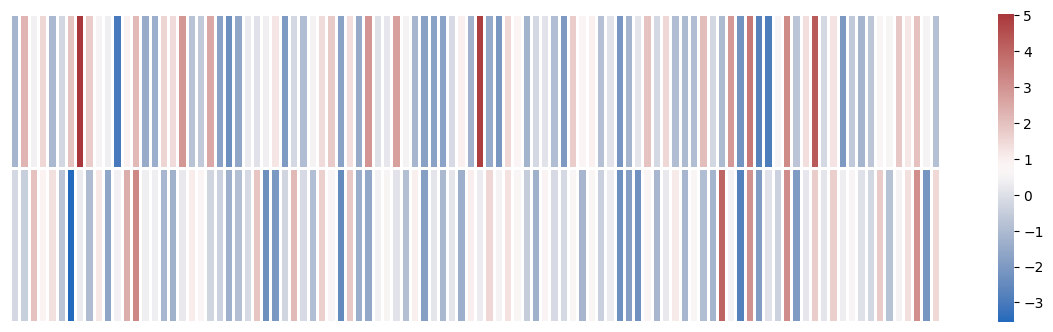

In [67]:
plt.figure(figsize=(15,4))
sns.heatmap([
            gensim_model.wv["king"], 
            #  gensim_model.wv["man"], 
             gensim_model.wv["woman"], 
            #  gensim_model.wv["king"] - gensim_model.wv["man"] + gensim_model.wv["woman"],
            #  gensim_model.wv["queen"],
            ], cbar=True, xticklabels=False, yticklabels=False,linewidths=1,cmap="vlag") 
plt.show()

In [68]:
x = gensim_model.wv["paris"] + gensim_model.wv["germany"] - gensim_model.wv["berlin"]

In [69]:
x

array([-1.0850439 ,  0.8012023 ,  2.2490902 ,  1.5788097 ,  4.233615  ,
        1.1966587 , -1.8977864 ,  1.6969332 ,  1.2296801 ,  0.7062972 ,
        2.0372047 ,  3.8895247 ,  2.3568423 ,  1.3482621 , -1.6394081 ,
        0.46530652,  0.89448416, -2.0564232 , -0.33188713,  0.80800515,
        1.8310115 ,  3.1423936 , -0.01036203, -0.8984867 ,  0.22286022,
        0.34369302, -0.16324633,  1.6581714 , -1.478504  , -2.1198044 ,
        1.9241906 ,  0.05779511,  2.0251937 ,  1.024333  , -0.7843025 ,
        1.1219721 ,  1.3580146 , -1.8301013 , -0.28910983,  1.8289146 ,
       -2.0309398 ,  2.6616242 , -0.6385451 , -1.2799706 , -1.7152315 ,
        0.73379904,  0.09257939, -0.85325927,  0.757046  ,  0.550164  ,
        1.7007626 ,  1.5163326 , -0.49477804,  1.1331115 , -1.5620904 ,
        1.4109603 ,  0.20774794,  3.2464082 , -2.074003  ,  0.60910046,
        0.8999353 ,  1.9570487 ,  1.3168272 , -1.2606208 , -2.5889254 ,
        0.46213105,  0.60631615,  3.8869047 ,  1.6894643 ,  0.03

In [70]:
gensim_model.wv["france"]

array([-1.52942210e-01,  1.85090077e+00,  8.45946550e-01,  9.66287255e-01,
        2.48687315e+00,  6.68191433e-01, -5.54575622e-01,  3.05972910e+00,
        1.44628000e+00,  9.37264025e-01,  1.86465037e+00,  2.42843032e+00,
       -7.88887367e-02,  5.60026348e-01, -4.46952790e-01,  5.28605878e-01,
        5.98024428e-01,  6.23562157e-01,  4.87793759e-02, -1.36928797e+00,
       -1.61808759e-01,  2.87456536e+00, -1.30059230e+00, -4.82081592e-01,
       -4.33132425e-02, -2.77455151e-01, -4.64999050e-01,  1.05459738e+00,
        4.82670575e-01, -1.74289966e+00,  1.14247787e+00, -8.22922409e-01,
        7.51151860e-01,  5.41984677e-01, -2.48103678e-01,  2.51797259e-01,
        8.75757158e-01, -1.51620913e+00, -5.33481054e-02,  7.36579120e-01,
       -7.47480690e-01,  2.12404084e+00, -3.81552905e-01, -1.16593444e+00,
       -9.12541807e-01,  1.58732927e+00,  2.63426065e-01, -8.08424234e-01,
       -6.89699829e-01,  3.96531910e-01,  2.06408048e+00,  2.02004170e+00,
       -1.35283053e-01,  

## Mini zadanie: Jak możemy znaleźć do czego odnosi się wektor x?